# Part 6: Why AUC, KS and log loss won't save you here

*Series: Who Will Stay Because of Us? Uplift Modelling and Causal Inference for Client Attrition*

Anyone who has built a churn model reaches for the same scorecard: ROC-AUC, PR-AUC, KS, Gini, log loss. Part 5 graded the uplift model with different tools: bins, Qini, uplift@k. This notebook explains why, and what the familiar metrics are still good for.

**In this notebook**

1. Two uplift models whose churn models score almost the same AUC, but whose uplift rankings are worlds apart.
2. ROC-AUC versus PR-AUC when churn is rare.
3. How KS, Gini, lift and thresholds all come from one decile table.
4. Log loss: what it rewards, and why calibration matters later.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.model_selection import train_test_split

from uplift_series import FEATURES, SERIES_SEED, analysis_pool, generate_bank
from uplift_series import plotting as P
from uplift_series.evaluation import churn_metrics, gains_table, qini_coefficient, uplift_at_k
from uplift_series.modeling import DEFAULT_XGB_PARAMS, TLearner, split_pool

P.set_style()
pd.set_option("display.float_format", "{:.3f}".format)

df = generate_bank(assignment="random", seed=SERIES_SEED)
train, test = split_pool(analysis_pool(df), test_size=0.3, seed=0)

## 1. Two good churn models, one useless uplift model

A very ordinary situation: the pricing benchmark table, which says how a client's fees compare with peers, lives in another system and never makes it into the modelling data. Build the T-learner twice:

- **Version A:** all features.
- **Version B:** the same, minus `pricing_gap`.

Each version contains two churn models (Model 1 for treated clients, Model 2 for control). Score them the way any churn model would be scored, on the test clients of their own group.

In [2]:
versions = {
    "A: all features": FEATURES,
    "B: without pricing gap": [f for f in FEATURES if f != "pricing_gap"],
}
treated_test = test[test["treated"] == 1]
control_test = test[test["treated"] == 0]

rows = {}
for name, feats in versions.items():
    model = TLearner(features=feats).fit(train)
    test[name] = model.predict_uplift(test)
    m1 = churn_metrics(treated_test["churned_6m"], model.predict_churn_with_pricing(treated_test))
    m2 = churn_metrics(control_test["churned_6m"], model.predict_churn_no_action(control_test))
    rows[name] = {
        "Model 1 (treated) ROC-AUC": m1["roc_auc"],
        "Model 2 (control) ROC-AUC": m2["roc_auc"],
        "Model 2 KS": m2["ks"],
        "Qini coefficient": qini_coefficient(test, name),
        "Uplift@20% (points)": 100 * uplift_at_k(test, name, 0.2),
    }
scorecard = pd.DataFrame(rows)
scorecard

,A: all features,B: without pricing gap
Model 1 (treated) ROC-AUC,0.856,0.788
Model 2 (control) ROC-AUC,0.739,0.737
Model 2 KS,0.378,0.374
Qini coefficient,4.968,-3.557
Uplift@20% (points),10.115,2.083


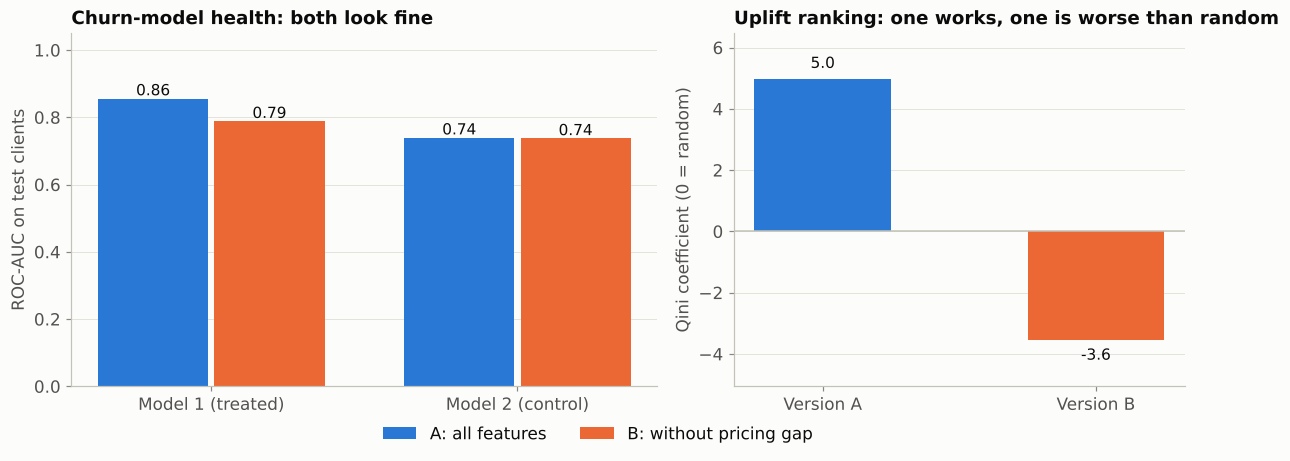

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.3, 1]})
names = list(versions)
colors = [P.BLUE, P.ORANGE]

ax = axes[0]
metrics = ["Model 1 (treated) ROC-AUC", "Model 2 (control) ROC-AUC"]
x = np.arange(len(metrics))
w = 0.36
for i, (name, color) in enumerate(zip(names, colors)):
    vals = scorecard.loc[metrics, name].to_numpy()
    bars = ax.bar(x + (i - 0.5) * (w + 0.02), vals, w, color=color, label=name)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", color=P.INK, fontsize=10)
ax.set_xticks(x, ["Model 1 (treated)", "Model 2 (control)"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("ROC-AUC on test clients")
ax.grid(axis="x", visible=False)
ax.set_title("Churn-model health: both look fine", fontsize=12)

ax = axes[1]
vals = scorecard.loc["Qini coefficient", names].to_numpy()
bars = ax.bar(np.arange(2), vals, 0.5, color=colors)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + (0.25 if v >= 0 else -0.25), f"{v:.1f}",
            ha="center", va="bottom" if v >= 0 else "top", color=P.INK, fontsize=10)
ax.axhline(0, color=P.BASELINE, linewidth=1)
ax.set_xticks(np.arange(2), ["Version A", "Version B"])
ax.set_ylim(min(vals.min(), 0) - 1.5, vals.max() + 1.5)
ax.set_ylabel("Qini coefficient (0 = random)")
ax.grid(axis="x", visible=False)
ax.set_title("Uplift ranking: one works, one is worse than random", fontsize=12)

fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout()
P.save(fig, "06_auc_vs_qini")
plt.show()

Both versions pass a churn-model review: Model 2 is essentially unchanged, and Model 1 still scores a strong AUC. Yet Version B's uplift ranking is **worse than random**.

The reason is that ROC-AUC asks *"does this model rank churners above stayers?"* Both versions can do that well using tenure, complaints, transaction trends and corporate events. Uplift asks a different question: *"who responds to pricing?"* In this bank, response is driven by the pricing gap. Without it, each model still predicts churn well, but the **difference** between the two models is mostly noise.

So: the AUC, KS and log loss of Model 1 and Model 2 are **health checks**. They should be reasonable. They are not evidence that the uplift ranking works. Only the uplift metrics from Part 5 are.

The rest of this notebook is a refresher on the churn metrics themselves, because they still matter for the churn model that builds the list in the first place.

## 2. ROC-AUC vs PR-AUC when churn is rare

Train an ordinary churn model on all 40,000 clients (churn rate about 7.5%) and look at it two ways.

In [4]:
full_train, full_test = train_test_split(df, test_size=0.3, stratify=df["churned_6m"], random_state=0)
churn_model = xgb.XGBClassifier(**DEFAULT_XGB_PARAMS).fit(full_train[FEATURES], full_train["churned_6m"])
p = churn_model.predict_proba(full_test[FEATURES])[:, 1]
y = full_test["churned_6m"].to_numpy()
cm = churn_metrics(y, p)
pd.Series(cm).to_frame("churn model on all clients")

,churn model on all clients
roc_auc,0.766
gini,0.532
ks,0.394
pr_auc,0.291
base_rate,0.075
log_loss,0.228
base_log_loss,0.267


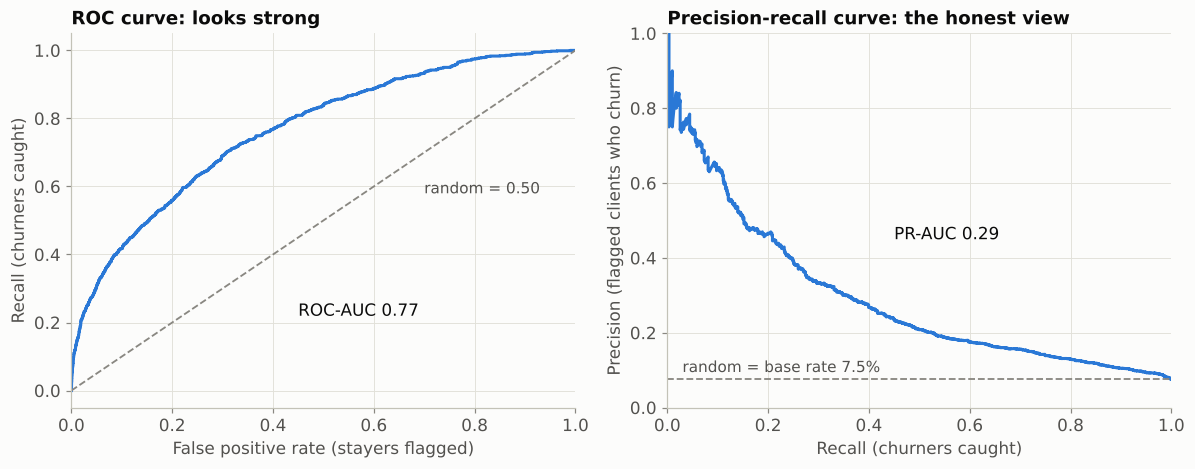

In [5]:
fpr, tpr, _ = roc_curve(y, p)
precision, recall, _ = precision_recall_curve(y, p)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
ax.plot(fpr, tpr, color=P.BLUE)
ax.plot([0, 1], [0, 1], color=P.INK_MUTED, linestyle="--", linewidth=1.2)
ax.text(0.45, 0.22, f"ROC-AUC {cm['roc_auc']:.2f}", color=P.INK)
ax.text(0.70, 0.58, "random = 0.50", ha="left", color=P.INK_SECONDARY, fontsize=10)
ax.set_xlabel("False positive rate (stayers flagged)")
ax.set_ylabel("Recall (churners caught)")
ax.set_title("ROC curve: looks strong", fontsize=12)

ax = axes[1]
ax.plot(recall, precision, color=P.BLUE)
ax.axhline(cm["base_rate"], color=P.INK_MUTED, linestyle="--", linewidth=1.2)
ax.text(0.03, cm["base_rate"] + 0.02, f"random = base rate {cm['base_rate']:.1%}", ha="left",
        color=P.INK_SECONDARY, fontsize=10)
ax.text(0.45, 0.45, f"PR-AUC {cm['pr_auc']:.2f}", color=P.INK)
ax.set_xlabel("Recall (churners caught)")
ax.set_ylabel("Precision (flagged clients who churn)")
ax.set_ylim(0, 1)
ax.set_title("Precision-recall curve: the honest view", fontsize=12)
for a in axes:
    a.set_xlim(0, 1)
fig.tight_layout()
P.save(fig, "06_roc_vs_pr")
plt.show()

- **ROC-AUC** is the probability that a random churner gets a higher score than a random stayer. Random guessing scores 0.5.
- **PR-AUC** summarises precision (of the clients flagged, how many really churn) across all recall levels. Random guessing scores the **base rate**, not 0.5.

With 7.5% churn, the ROC curve looks comfortable because false positives are measured against a huge pool of stayers: flagging a thousand stayers by mistake barely moves the false positive rate. The PR curve measures the flagged list directly. That is where RM time goes, so with rare churn **report PR-AUC alongside ROC-AUC, and always read it against the base rate.**

## 3. One table behind KS, Gini, lift and thresholds

Sort clients by churn score and cut into ten deciles. Each row below is a threshold: *flag everyone in this decile and above*.

In [6]:
gains = gains_table(y, p, n_bins=10)
gains[["clients", "churners", "churners_in_bin_rate", "recall_tpr", "fpr", "cum_precision", "cum_lift", "tpr_minus_fpr"]]

,clients,churners,churners_in_bin_rate,recall_tpr,fpr,cum_precision,cum_lift,tpr_minus_fpr
bin,,,,,,,,
1,1200,341,0.284,0.378,0.077,0.284,3.785,0.301
2,1200,135,0.113,0.528,0.173,0.198,2.642,0.355
3,1200,108,0.090,0.648,0.272,0.162,2.161,0.376
4,1200,91,0.076,0.749,0.372,0.141,1.873,0.378
5,1200,67,0.056,0.824,0.474,0.124,1.647,0.350
6,1200,49,0.041,0.878,0.577,0.110,1.463,0.300
7,1200,43,0.036,0.926,0.682,0.099,1.322,0.244
8,1200,41,0.034,0.971,0.786,0.091,1.214,0.185
9,1200,16,0.013,0.989,0.893,0.083,1.099,0.096


In [7]:
top_decile_lift = gains.loc[1, "cum_lift"]
print(f"Top-decile lift: {top_decile_lift:.1f}x  (precision in decile 1 / base rate)")
print(f"KS from the table: {gains['tpr_minus_fpr'].max():.2f}  (exact KS over every cut-off: {cm['ks']:.2f})")
print(f"Gini = 2 x ROC-AUC - 1 = {cm['gini']:.2f}")

Top-decile lift: 3.8x  (precision in decile 1 / base rate)
KS from the table: 0.38  (exact KS over every cut-off: 0.39)
Gini = 2 x ROC-AUC - 1 = 0.53


Everything on the usual scorecard is in that table:

- each row's **recall** and **FPR** is one point on the ROC curve; each row's recall and **precision** is one point on the PR curve;
- **top-decile lift** is decile 1's precision divided by the base rate;
- **KS** is the largest gap between recall and FPR (the table gives a close approximation; the exact value checks every cut-off);
- **Gini** is a rescaling of ROC-AUC.

### Choosing a threshold

AUC never picks a threshold; this table does. Three common rules:

1. **Capacity:** RMs can handle a fixed number of clients, so cut there.
2. **Break-even precision:** if a call costs C and a churner reached is worth V on average (including the chance the call works), call while the *bin's own* churn rate (`churners_in_bin_rate`) is above C / V.
3. **KS point:** the cut-off with the best statistical separation. Fine for comparing models, but it ignores capacity and money.

Rule 2 quietly assumes every churner is equally likely to be saved by a call. Uplift modelling replaces that assumption with a client-by-client estimate, which is the subject of Part 7.

## 4. Log loss and calibration

ROC-AUC only checks the **order** of scores. **Log loss** (binary cross-entropy) checks the scores themselves: it punishes confident wrong probabilities heavily. A model that always predicts the base rate sets the bar to beat.

In [8]:
print(f"Model log loss:             {cm['log_loss']:.3f}")
print(f"Always predict base rate:   {cm['base_log_loss']:.3f}")

calib = pd.DataFrame({"predicted": p, "actual": y})
calib["bin"] = pd.qcut(calib["predicted"].rank(method="first"), 10, labels=range(1, 11))
calib.groupby("bin", observed=True)[["predicted", "actual"]].mean().rename_axis("decile (1 = lowest scores)")

Model log loss:             0.228
Always predict base rate:   0.267


,predicted,actual
decile (1 = lowest scores),,
1,0.015,0.008
2,0.024,0.013
3,0.032,0.034
4,0.039,0.036
5,0.048,0.041
6,0.057,0.056
7,0.070,0.076
8,0.087,0.090
9,0.116,0.113


Predicted and actual churn rates track each other across deciles, so this model's scores can be read as real probabilities. That matters as soon as probabilities feed a calculation, such as uplift times revenue in Part 7. A model trained with class weights to handle rare churn can keep the same AUC while its probabilities drift far from reality, so recalibrate after reweighting.

## Takeaways

- **ROC-AUC, KS, Gini and log loss judge a churn ranking, not an uplift ranking.** Two churn models can both score well while their difference, the uplift, is useless.
- Use them as **health checks** on Model 1 and Model 2; judge the uplift model with **bins, Qini and uplift@k**.
- With rare churn, **PR-AUC and precision in the top decile** describe the RM list more honestly than ROC-AUC. Read PR-AUC against the base rate.
- KS, lift, Gini and thresholds all come from **one gains table**; thresholds are a business choice (capacity or break-even), not a statistical one.
- **Log loss and calibration** matter whenever probabilities are used as numbers.

**Next, Part 7:** turning uplift into dollars: revenue, the cost of a concession, and why the biggest loyal clients are the most expensive ones to discount.